# PyTorch 使用：从张量到图像分类训练


**先修知识**：Python 的函数、类、继承、列表、字典和 `for` 循环。

**运行方式**：在 Jupyter 或 VS Code 中选择当前项目的 Python 环境，然后执行“全部运行”。环境需要 `torch`、`torchvision`、`torchsummary`、`numpy`、`pandas`、`matplotlib`、`Pillow`；若无法选择内核，在该环境安装 `ipykernel`。所有数据均现场生成，**不下载数据或预训练权重**。CPU 即可运行；有 CUDA 时训练部分自动使用 GPU。临时图片、CSV 和权重在示例结束后自动清理。

## 学习路线

1. Tensor：创建、类型、索引、广播、矩阵运算、形状与设备。
2. Autograd：计算图、反向传播、梯度清零与关闭梯度。
3. 数据：PIL、transforms、Dataset、DataLoader、ImageFolder。
4. 模型：Module、卷积/池化/激活/全连接、BatchNorm、Dropout。
5. 结构：Sequential、Inception 式分支、残差连接、权重初始化。
6. 训练：损失、优化器、训练/验证、最佳权重、曲线。
7. 推理：加载权重、单张图片、类别索引与概率。

**贯穿全文的约定**：`N` 是批量大小，`C` 是通道数，`H/W` 是高/宽，`K` 是类别数。图像张量通常为 `[N, C, H, W]`，分类器输出为 `[N, K]`。


## 1. 导入与运行环境

`torch` 负责张量与自动微分；`torch.nn` 提供网络层和损失；`torch.optim` 更新参数；`torchvision` 提供视觉数据处理与常见模型。

`manual_seed` 使本教程的随机示例更易复现，但不保证不同硬件、版本之间逐位相同。模型和参与同一次运算的张量必须位于同一设备；`.to(device)` 对张量需接收返回值，对模型则会移动其参数与缓冲区。


In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms, datasets, models
from torchsummary import summary

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# 小型 CPU 教学任务限制线程数，避免过多线程调度开销。
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("device:", device)


PyTorch: 2.15.0+cpu
device: cpu


## 2. Tensor：数值、类型、形状

Tensor 是带有 `shape`、`dtype` 和 `device` 的多维数组。模型参数和输入一般用 `float32`，类别索引用 `int64`（即 `torch.long`）。整数 Tensor 不能直接成为需要梯度的参数。

| API | 含义 |
|---|---|
| `torch.tensor(data)` | 从数据构造张量，复制数据 |
| `zeros` / `ones` / `full` | 创建常量张量 |
| `arange` / `linspace` | 等步长 / 指定点数的序列 |
| `rand` / `randn` / `randint` | 均匀浮点 / 标准正态 / 随机整数 |
| `zeros_like(x)` | 沿用输入的形状、类型和设备 |
| `x.shape`、`x.size(0)`、`x.ndim` | 形状、某一维长度、维数 |
| `x.numel()`、`x.dtype`、`x.device` | 元素总数、类型、设备 |


In [2]:
a = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)
labels = torch.tensor([0, 2], dtype=torch.long)
print(a)
print("shape:", a.shape, "size(0):", a.size(0), "ndim:", a.ndim)
print("numel:", a.numel(), "dtype:", a.dtype, "device:", a.device)
print("zeros:", torch.zeros(2, 3))
print("ones:", torch.ones(1, 3))
print("full:", torch.full((2,), 7))
print("arange:", torch.arange(0, 6, 2))
print("linspace:", torch.linspace(0, 1, 3))
print("random shapes:", torch.rand(2, 3).shape, torch.randn(2, 3).shape)
print("randint:", torch.randint(0, 3, (4,)))
print("zeros_like:", torch.zeros_like(a))
print("type conversion:", labels.float().dtype, a.long().dtype)


tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3]) size(0): 2 ndim: 2
numel: 6 dtype: torch.float32 device: cpu
zeros: tensor([[0., 0., 0.],
        [0., 0., 0.]])
ones: tensor([[1., 1., 1.]])
full: tensor([7, 7])
arange: tensor([0, 2, 4])
linspace: tensor([0.0000, 0.5000, 1.0000])
random shapes: torch.Size([2, 3]) torch.Size([2, 3])
randint: tensor([0, 1, 1, 2])
zeros_like: tensor([[0., 0., 0.],
        [0., 0., 0.]])
type conversion: torch.float32 torch.int64


### 2.1 索引、切片、归约与标量

索引规则类似 NumPy。`dim` 指“沿哪个轴做运算”：对 `[N, K]` 的分类分数，`dim=1` 表示在每个样本的类别轴上求最大值；不是在整个批次中选一个类别。

`.item()` 只能取**单元素**张量的 Python 数值；GPU 上取值会发生同步，不要在不需要时逐元素调用。


In [3]:
scores = torch.tensor([[1., 4., 2.], [5., 0., 3.]])
print("first row:", scores[0], "last column:", scores[:, -1])
print("mask:", scores[scores > 2])
print("sum:", scores.sum().item(), "mean:", scores.mean().item())
values, indices = torch.max(scores, dim=1)
print("max values:", values, "class indices:", indices)
print("argmax:", scores.argmax(dim=1))
print("correct count:", (indices == torch.tensor([1, 0])).sum().item())
print("keepdim:", scores.mean(dim=1, keepdim=True).shape)


first row: tensor([1., 4., 2.]) last column: tensor([2., 3.])
mask: tensor([4., 5., 3.])
sum: 15.0 mean: 2.5
max values: tensor([4., 5.]) class indices: tensor([1, 0])
argmax: tensor([1, 0])
correct count: 2
keepdim: torch.Size([2, 1])


### 2.2 逐元素运算、广播与矩阵乘法

`*` 是逐元素乘法，`@` / `torch.matmul` 才是矩阵乘法。广播从末尾维度对齐：对应长度相等或其中一个为 1 才能扩展

`[N, C, H, W]` 图像加通道偏置时，把 `[C]` 显式变成 `[1, C, 1, 1]`。


In [4]:
x = torch.arange(6, dtype=torch.float32).reshape(2, 3)
print("elementwise:", x * 2)
print("broadcast bias:", x + torch.tensor([10., 20., 30.]))
weight = torch.ones(3, 4)
print("matrix product:", (x @ weight).shape)
images = torch.zeros(2, 3, 4, 4)
channel_bias = torch.tensor([1., 2., 3.]).reshape(1, 3, 1, 1)
print("per-channel bias:", (images + channel_bias)[0, :, 0, 0])


elementwise: tensor([[ 0.,  2.,  4.],
        [ 6.,  8., 10.]])
broadcast bias: tensor([[10., 21., 32.],
        [13., 24., 35.]])
matrix product: torch.Size([2, 4])
per-channel bias: tensor([1., 2., 3.])


### 2.3 改形状、换轴、拼接：最常见的读代码障碍

| API | 操作 | 注意 |
|---|---|---|
| `reshape` / `view` | 元素次序不变，重新分组 | `-1` 自动推导一个维度；`view` 要求步幅兼容 |
| `flatten(start_dim=1)` | 保留 batch，把后面的维度压平 | `[N,C,H,W] → [N,C×H×W]` |
| `permute` / `transpose` | 调换轴 | 不是用 `reshape` 替代换轴 |
| `unsqueeze` / `squeeze` | 增加 / 删除长度为 1 的轴 | 优先指定 `dim`，避免删掉 batch 轴 |
| `cat` | 沿已有轴连接 | 除连接轴外，其余维度必须一致 |
| `stack` | 插入新轴并堆叠 | 所有输入形状必须一致 |

`permute` 后常为非连续内存。需要 `view` 时先 `.contiguous()`；不关心是否复制时用 `.reshape()`。不要只为“能运行”改 shape，必须先明确每个轴的语义。


In [5]:
batch = torch.arange(2 * 3 * 4 * 4).reshape(2, 3, 4, 4)
print("flatten:", torch.flatten(batch, start_dim=1).shape)
print("view:", batch.view(batch.size(0), -1).shape)
nhwc = batch.permute(0, 2, 3, 1)
print("NHWC:", nhwc.shape, "contiguous:", nhwc.is_contiguous())
assert torch.equal(nhwc.contiguous().view(2, -1), nhwc.reshape(2, -1))
single_image = torch.zeros(3, 4, 4)
print("add batch:", single_image.unsqueeze(0).shape)
print("remove batch:", single_image.unsqueeze(0).squeeze(0).shape)
branch_a, branch_b = torch.zeros(2, 4, 8, 8), torch.ones(2, 6, 8, 8)
print("cat channels:", torch.cat([branch_a, branch_b], dim=1).shape)
print("stack images:", torch.stack([single_image, single_image], dim=0).shape)


flatten: torch.Size([2, 48])
view: torch.Size([2, 48])
NHWC: torch.Size([2, 4, 4, 3]) contiguous: False
add batch: torch.Size([1, 3, 4, 4])
remove batch: torch.Size([3, 4, 4])
cat channels: torch.Size([2, 10, 8, 8])
stack images: torch.Size([2, 3, 4, 4])


### 2.4 NumPy、复制和设备

CPU Tensor 的 `.numpy()` 可能共享内存；`torch.from_numpy` 也与原数组共享内存。`clone()` 才复制张量数据；`detach()` 只切断梯度关系，**不保证独立存储**。

从模型输出转 NumPy 的常用写法是 `output.detach().cpu().numpy()`。`.cpu()` 把数据移回 CPU；`numpy()` 不能直接处理 CUDA 张量或仍需梯度的张量。


In [6]:
array = np.array([1., 2.], dtype=np.float32)
shared = torch.from_numpy(array)
shared[0] = 9
assert array[0] == 9
independent = shared.clone()
shared[0] = 3
assert independent[0].item() == 9
on_device = a.to(device)
print("on device:", on_device.device)
print("numpy:", on_device.detach().cpu().numpy())


on device: cpu
numpy: [[1. 2. 3.]
 [4. 5. 6.]]


## 3. Autograd：梯度不是自动更新参数

把可训练 Tensor 设为 `requires_grad=True` 后，PyTorch 会记录其参与的可微运算。`loss.backward()` 根据链式法则计算梯度，并累加到叶子 Tensor 的 `.grad` 中；**它不会更新参数**。

例：$y=x^2+3x$，则 $dy/dx=2x+3$。在 $x=2$ 时，梯度应为 7。通常对标量损失调用 `backward()`。


In [7]:
x = torch.tensor(2.0, requires_grad=True)
y = x ** 2 + 3 * x
y.backward()
print("y:", y.item(), "gradient:", x.grad.item())
assert x.grad.item() == 7.0

# 再计算一张新图。梯度不会自动清零，所以累加为 14。
(x ** 2 + 3 * x).backward()
assert x.grad.item() == 14.0
x.grad = None
(x ** 2 + 3 * x).backward()
assert x.grad.item() == 7.0

with torch.no_grad():
    untracked = x * 2
print("requires_grad:", (x * 2).requires_grad, untracked.requires_grad)
print("detach:", y.detach().requires_grad)


y: 10.0 gradient: 7.0
requires_grad: True False
detach: False


### 3.1 一次手写梯度下降

一次更新是 `参数 ← 参数 − 学习率 × 梯度`。更新参数本身不应加入下一张计算图，所以放在 `no_grad()` 中。正式训练使用优化器完成更新和清零。

不要在计算损失前把输出 `.detach()`，也不要用 `.item()` 的结果重新拼损失：这样会断开训练所需的计算图。通常每个 batch 前重新前向并构图，不需要 `retain_graph=True`。


In [8]:
w = torch.tensor(0.0, requires_grad=True)
for _ in range(12):
    loss = (w - 3) ** 2
    loss.backward()
    with torch.no_grad():
        w -= 0.2 * w.grad
    w.grad = None
print("w approaches 3:", w.item())
assert abs(w.item() - 3) < 0.02


w approaches 3: 2.993469715118408


## 4. 图像预处理：PIL → Tensor → 标准化

PIL 的 RGB 图片大小记作 `(宽, 高)`；NumPy 常为 `[H,W,C]`；模型需要 `[C,H,W]` 或带批次的 `[N,C,H,W]`。下面使用传统 `torchvision.transforms` 接口。

- `Compose`：按顺序应用变换。
- `Resize((H,W))`：直接调整到指定高宽；`Resize(s)` 则按短边缩放并保持比例。
- `CenterCrop`：中心裁剪；`RandomResizedCrop`：随机裁剪后缩放。
- `RandomHorizontalFlip`：随机水平翻转，通常只用于训练。
- `ToTensor`：对这里的 uint8/PIL 图像，将 `[0,255]` 转为浮点 `[0,1]`，并转为 CHW。不是对任意输入都自动除以 255。
- `Normalize(mean,std)`：各通道分别做 `(x-mean)/std`，不是再调整图片大小。

`RGB` 需要 3 组均值/标准差，灰度需要 1 组。标准化参数由数据和模型要求决定，下面的数值只是本教程的设置。


In [9]:
raw = np.zeros((28, 36, 3), dtype=np.uint8)
raw[..., 0] = 220
raw[6:22, 8:28, 1] = 180
pil_image = Image.fromarray(raw).convert("RGB")
train_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.RandomCrop(24),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
eval_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.CenterCrop(24),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
image_tensor = eval_transform(pil_image)
print("PIL size:", pil_image.size, "tensor shape:", image_tensor.shape)
print("normalized range:", image_tensor.min().item(), image_tensor.max().item())
print("random resized crop:", transforms.RandomResizedCrop(24)(pil_image).size)
gray_tensor = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])(pil_image)
print("gray:", gray_tensor.shape)


PIL size:

 (36, 28) tensor shape: torch.Size([3, 24, 24])
normalized range: -1.0 0.7254902124404907
random resized crop: (24, 24)
gray: torch.Size([1, 28, 36])


### 4.1 显示前反标准化

`imshow` 需要 HWC，不是 CHW。显示标准化后的图像时，应先反标准化，再转 NumPy；不要把反标准化后的数据喂回要求标准化输入的模型。


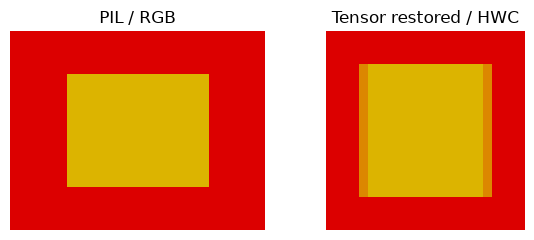

In [10]:
restored = (image_tensor * 0.5 + 0.5).clamp(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
axes[0].imshow(pil_image)
axes[0].set_title("PIL / RGB")
axes[1].imshow(restored.permute(1, 2, 0).numpy())
axes[1].set_title("Tensor restored / HWC")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Dataset 和 DataLoader：一个样本与一批样本

`Dataset` 回答“有多少样本、如何按索引取一个样本”，通常返回 `(image, label)`；`DataLoader` 负责打乱、组合成 batch 和迭代。继承 `Dataset` 并实现 `__len__`、`__getitem__` 即可定义自己的数据集。

下面生成三种主色的 RGB 小图片。它们让训练流程可以离线运行，但不代表真实图像任务的难度。训练集和验证集使用不同随机种子，验证不使用随机增强。


In [11]:
class ColorDataset(Dataset):
    def __init__(self, count, seed, transform):
        self.transform = transform
        rng = np.random.default_rng(seed)
        self.labels = np.arange(count, dtype=np.int64) % 3
        pixels = rng.integers(0, 35, size=(count, 28, 28, 3), dtype=np.uint8)
        for i, label in enumerate(self.labels):
            pixels[i, :, :, label] = rng.integers(185, 255, size=(28, 28), dtype=np.uint8)
        self.pixels = pixels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.pixels[index]).convert("RGB")
        return self.transform(image), int(self.labels[index])


train_data = ColorDataset(96, seed=1, transform=train_transform)
val_data = ColorDataset(39, seed=2, transform=eval_transform)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_data, batch_size=16, shuffle=True,
                          num_workers=0, generator=loader_generator)
val_loader = DataLoader(val_data, batch_size=16, shuffle=False, num_workers=0)
images, targets = next(iter(train_loader))
print("samples:", len(train_data), "batches:", len(train_loader))
print("images:", images.shape, images.dtype)
print("targets:", targets.shape, targets.dtype, targets)
assert images.shape == (16, 3, 24, 24)
assert targets.dtype == torch.long


samples: 96 batches: 6
images: torch.Size([16, 3, 24, 24]) torch.float32
targets: torch.Size([16]) torch.int64 tensor([1, 0, 2, 2, 0, 2, 1, 1, 0, 1, 0, 2, 0, 1, 1, 1])


### 5.1 读懂 DataLoader 的配置

- `batch_size=16`：每批最多 16 个样本，不是类别数量。
- `shuffle=True`：每轮重排样本，常用于训练；验证通常设为 `False`。
- `drop_last=False`（默认）：保留不足一批的样本。因此统计指标不能假设每批都一样大。
- `num_workers=0`：主进程加载数据，最适合 Notebook 的起步与排错。Windows 脚本使用多进程时还需要 `if __name__ == "__main__":` 保护入口。
- `pin_memory=True` 可配合 CUDA 数据传输；不是 CPU 示例的必要设置。

若数据已是 Tensor，`TensorDataset` 可以直接按第 0 维配对。`iter(loader)` 建立迭代器，`next(...)` 取下一批；正式训练使用 `for images, targets in loader:`。


In [12]:
tensor_data = TensorDataset(torch.randn(5, 4), torch.tensor([0, 1, 0, 1, 0]))
small_loader = DataLoader(tensor_data, batch_size=2, shuffle=False)
print("last batch kept:", [len(y) for _, y in small_loader])
assert [len(y) for _, y in small_loader] == [2, 2, 1]


last batch kept: [2, 2, 1]


### 5.2 ImageFolder：从目录名称产生标签

`datasets.ImageFolder(root, transform=...)` 适合 `root/类别名/图片.png` 这样的目录。类别目录按名称排序，标签从 0 开始；`classes` 和 `class_to_idx` 是理解预测索引的关键。

下面实际创建两张临时图片并读取。真实任务应使用独立的训练/验证目录，并检查两者的 `class_to_idx` 完全一致。不能把文件夹遍历顺序当作固定类别约定。


In [13]:
with TemporaryDirectory() as temp_dir:
    root = Path(temp_dir)
    for class_name, color in [("red", (230, 20, 20)), ("green", (20, 230, 20))]:
        folder = root / class_name
        folder.mkdir()
        Image.new("RGB", (28, 28), color=color).save(folder / "sample.png")
    folder_data = datasets.ImageFolder(root, transform=eval_transform)
    print("classes:", folder_data.classes)
    print("class_to_idx:", folder_data.class_to_idx)
    folder_images, folder_labels = next(iter(DataLoader(folder_data, batch_size=2)))
    print("batch:", folder_images.shape, folder_labels)
    assert folder_data.class_to_idx == {"green": 0, "red": 1}


classes: ['green', 'red']
class_to_idx: {'green': 0, 'red': 1}
batch: torch.Size([2, 3, 24, 24]) tensor([0, 1])


### 5.3 random_split、Subset 与训练/验证/测试边界

`random_split(dataset, [训练长度, 验证长度], generator=...)` 返回两个 `Subset`，不复制底层数据。固定 generator 可复现划分；它是随机划分，**不会自动分层保持类别比例**。

重要陷阱：两个 Subset 引用同一个 dataset，如果直接共享带随机增强的 dataset，验证集也会随机变化。下面先划分索引，再为两组索引提供不同 transform 的数据视图。修改一个共享 dataset 的 `.transform` 并不能得到两套独立预处理。

训练集用于求梯度；验证集用于选模型；测试集留到最终评估，不能用测试表现反复调参。时间序列、同一患者/物体的相关图片等不能机械地随机逐图划分，应按任务隔离，避免泄漏。


In [14]:
from torch.utils.data import random_split, Subset

base_train_view = ColorDataset(60, seed=9, transform=train_transform)
base_eval_view = ColorDataset(60, seed=9, transform=eval_transform)
split_train, split_val = random_split(
    base_train_view, [48, 12], generator=torch.Generator().manual_seed(SEED)
)
train_subset = Subset(base_train_view, split_train.indices)
val_subset = Subset(base_eval_view, split_val.indices)
assert set(train_subset.indices).isdisjoint(val_subset.indices)
assert set(train_subset.indices) | set(val_subset.indices) == set(range(60))
print("split lengths:", len(train_subset), len(val_subset))
print("Subset shares its dataset:", split_train.dataset is split_val.dataset)


split lengths: 48 12
Subset shares its dataset: True


### 5.4 内置数据集：FashionMNIST 的接口

`torchvision.datasets.FashionMNIST(root, train=True/False, transform=..., download=...)` 返回灰度服饰图像与 0～9 的标签，单图原始尺寸为 28×28。`train=True` 表示官方训练部分，`False` 表示官方测试部分，**不等于模型的 train/eval 模式**。

以下仅展示调用模板，不执行下载。准备好本地数据后，去掉注释即可使用；没有本地文件时 `download=False` 会报错，不会悄悄生成替代数据。由官方训练部分划分验证集，最终测试部分保留独立。

灰度网络的首层应为 `in_channels=1`，输出头应为 10 类；若改为彩色数据，要同步检查通道、预处理和类别数，而不只是更换路径。


In [15]:
fashion_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
])
# 需要本地 FashionMNIST 文件时再启用，整份教程不依赖这些文件。
# fashion_train = datasets.FashionMNIST(
#     root="data", train=True, transform=fashion_transform, download=False
# )
# fashion_test = datasets.FashionMNIST(
#     root="data", train=False, transform=fashion_transform, download=False
# )
print("FashionMNIST transform:", fashion_transform)


FashionMNIST transform: Compose(
    Resize(size=(28, 28), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


### 5.5 正确计算 Normalize 所需的逐通道 mean/std

只用**训练部分**、不做随机增强且未 Normalize 的像素统计均值和标准差；不能把验证/测试数据混入。每个通道的分母是该通道的像素数 `N×H×W`，不是再乘通道数。Normalize 要求的是标准差 `sqrt(variance)`，不是方差。

下面用小数据展示：`dim=(0,2,3)` 表示消去 batch、高、宽，仅保留通道轴；`correction=0` 使用总体标准差。真实大数据应分批累积统计，避免一次堆进内存。数据增强后分布可能变化，统计策略需与任务约定一致。


In [16]:
unscaled = torch.from_numpy(train_data.pixels.copy()).permute(0, 3, 1, 2).float() / 255.0
channel_mean = unscaled.mean(dim=(0, 2, 3))
channel_std = unscaled.std(dim=(0, 2, 3), correction=0)
print("training pixel mean:", channel_mean)
print("training pixel std:", channel_std)
normalized = (unscaled - channel_mean[None, :, None, None]) / channel_std[None, :, None, None]
assert torch.allclose(normalized.mean((0, 2, 3)), torch.zeros(3), atol=1e-5)
assert torch.allclose(normalized.std((0, 2, 3), correction=0), torch.ones(3), atol=1e-5)
# 只是统计演示；不在训练中途更换前面固定的 0.5/0.5 预处理约定。


training pixel mean: tensor([0.3316, 0.3314, 0.3315])
training pixel std: tensor([0.3786, 0.3785, 0.3784])


## 6. nn.Module：模型为什么要写成类

`nn.Module` 管理子层、可训练参数、缓冲区以及训练/评估状态。

1. `__init__` 中先调用 `super().__init__()`，然后把网络层赋给 `self.xxx`，使它们被注册。
2. `forward(self, x)` 描述数据如何流过这些层。
3. 使用 `model(x)`，不要直接调用 `model.forward(x)`，前者保留 Module 的钩子等调用机制。
4. `model.parameters()` 交给优化器；`state_dict()` 用于保存参数和缓冲区。

`nn.Sequential` 按顺序连接层，适合直线结构。需要分支或残差时，在 `forward` 中显式描述。不要把应注册的层只放在普通 Python 列表中；需要动态层列表时使用 `nn.ModuleList`。


In [17]:
class LinearClassifier(nn.Module):
    def __init__(self, input_features=4, num_classes=3):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_features, 8),
            nn.ReLU(),
            nn.Linear(8, num_classes),
        )

    def forward(self, x):
        return self.layers(x)


linear_model = LinearClassifier()
print(linear_model)
print("output:", linear_model(torch.randn(2, 4)).shape)
for name, parameter in linear_model.named_parameters():
    print(name, tuple(parameter.shape), "trainable:", parameter.requires_grad)
print("parameter count:", sum(p.numel() for p in linear_model.parameters()))


LinearClassifier(
  (layers): Sequential(
    (0): Linear(in_features=4, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=3, bias=True)
  )
)
output: torch.Size([2, 3])
layers.0.weight (8, 4) trainable: True
layers.0.bias (8,) trainable: True
layers.2.weight (3, 8) trainable: True
layers.2.bias (3,) trainable: True
parameter count: 67


## 7. 卷积与池化：边看 API 边推导 shape

`nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)` 接收 NCHW。卷积核权重形状为 `[C_out, C_in/groups, kH, kW]`；`bias` 的形状为 `[C_out]`。卷积在每个位置共享权重。

单个空间轴的输出长度为：

$$L_{out}=\left\lfloor\frac{L_{in}+2p-d(k-1)-1}{s}+1\right\rfloor$$

这里 `k` 是核大小、`s` 是步幅、`p` 是填充、`d` 是 dilation（默认 1）；下面池化均使用默认 `ceil_mode=False`。

例如 `24 → Conv(k=3,p=1,s=1) → 24 → MaxPool(k=2,s=2) → 12`。

- `ReLU` 逐元素取 `max(0,x)`，不改变 shape；`Sigmoid` 将数值映射到 `(0,1)`，`Tanh` 映射到 `(-1,1)`。
- `MaxPool2d` 取局部最大值；`AvgPool2d` 取局部平均值，均不改变通道数。
- `AdaptiveAvgPool2d((1,1))` 把每个通道的空间图汇总成一个值；可在一定范围内解除全连接层对固定输入尺寸的依赖，但前面的层仍要求输入足够大。
- `Linear(in_features,out_features)` 作用于最后一维。CNN 通常先 flatten 为 `[N,C×H×W]` 再接它。


In [18]:
x = torch.randn(2, 3, 24, 24)
conv = nn.Conv2d(3, 8, kernel_size=3, stride=1, padding=1)
x = conv(x)
print("conv weight:", conv.weight.shape, "output:", x.shape)
x = nn.ReLU()(x)
x = nn.MaxPool2d(kernel_size=2, stride=2)(x)
print("maxpool:", x.shape)
x = nn.AvgPool2d(kernel_size=2, stride=2)(x)
print("avgpool:", x.shape)
x = nn.AdaptiveAvgPool2d((1, 1))(x)
print("adaptive avgpool:", x.shape)
x = torch.flatten(x, 1)
print("flatten:", x.shape, "linear:", nn.Linear(8, 3)(x).shape)
print("sigmoid:", nn.Sigmoid()(torch.tensor([-2., 0., 2.])))
print("tanh:", nn.Tanh()(torch.tensor([-2., 0., 2.])))


conv weight: torch.Size([8, 3, 3, 3]) output: torch.Size([2, 8, 24, 24])
maxpool: torch.Size([2, 8, 12, 12])
avgpool: torch.Size([2, 8, 6, 6])
adaptive avgpool: torch.Size([2, 8, 1, 1])
flatten: torch.Size([2, 8]) linear: torch.Size([2, 3])
sigmoid: tensor([0.1192, 0.5000, 0.8808])
tanh: tensor([-0.9640,  0.0000,  0.9640])


### 7.1 BatchNorm、Dropout 与 train / eval

`BatchNorm2d(C)` 针对每个通道进行归一化。默认配置下，训练时使用当前 batch 统计并更新 `running_mean` / `running_var`；评估时使用累计统计。`weight`、`bias` 可训练，累计统计是**缓冲区**而非参数，仍会进入 `state_dict`。

`Dropout(p)` 训练时随机置零并对保留值缩放；评估时直接通过。`p` 是丢弃概率。

**两个独立开关**：

| 操作 | 改变层的行为 | 记录梯度 |
|---|---|---|
| `model.train()` | 训练模式，影响 BatchNorm/Dropout | 本身不改变梯度开关 |
| `model.eval()` | 评估模式，等同于 `train(False)` | 本身不关闭梯度 |
| `torch.no_grad()` | 不改变模式 | 关闭梯度记录 |
| `torch.inference_mode()` | 不改变模式 | 更严格的推理上下文，适合纯推理 |

验证/预测通常同时使用 `eval()` 和关闭梯度；训练下一轮前要重新 `train()`。


In [19]:
normalizer = nn.BatchNorm2d(3)
probe = torch.randn(4, 3, 6, 6)
normalizer.train()
_ = normalizer(probe)
print("BatchNorm state:", list(normalizer.state_dict()))
normalizer.eval()
print("eval shape:", normalizer(probe).shape)

dropout = nn.Dropout(p=0.5)
probe = torch.ones(4, 6)
dropout.train()
print("train dropout:\n", dropout(probe))
dropout.eval()
assert torch.equal(dropout(probe), probe)
print("eval dropout leaves input unchanged")


BatchNorm state: ['weight', 'bias', 'running_mean', 'running_var', 'num_batches_tracked']
eval shape: torch.Size([4, 3, 6, 6])
train dropout:
 tensor([[0., 0., 0., 2., 0., 2.],
        [2., 0., 0., 0., 0., 2.],
        [2., 0., 2., 0., 0., 2.],
        [0., 0., 0., 2., 0., 0.]])
eval dropout leaves input unchanged


### 7.1.1 nn 与 nn.functional：同一类操作，两种接口

`torch.nn.functional`（常写作 `F`）直接对 Tensor 运算，例如 `F.relu(x)`、`F.max_pool2d(x,2)`。`nn.ReLU()` 则是一个 Module，可放入 Sequential。

**Dropout 尤其容易误用**：`nn.Dropout` 自动跟随父模型模式；`F.dropout` 的 `training` 默认是 `True`，不会自动读取父模型状态。在 `forward` 中应写 `F.dropout(x, p=0.5, training=self.training)`。`no_grad()` 也不会关闭随机 Dropout。

参数层通常优先使用 `nn.Conv2d` / `nn.Linear`，由 Module 自动注册权重；functional 接口则要求调用方自行提供所需参数。


In [20]:
import torch.nn.functional as F

class FunctionalDropout(nn.Module):
    def forward(self, x):
        x = F.relu(x)
        return F.dropout(x, p=0.5, training=self.training)


functional_model = FunctionalDropout().eval()
probe = torch.ones(4, 6)
assert torch.equal(functional_model(probe), probe)
print("functional dropout respects eval when training=self.training")
print("functional pooling:", F.max_pool2d(torch.randn(2, 3, 8, 8), kernel_size=2).shape)


functional dropout respects eval when training=self.training
functional pooling: torch.Size([2, 3, 4, 4])


### 7.2 一个可训练的小型 CNN

下面的 `features` 提取空间特征，`classifier` 给出每个类别的原始分数（logits）。最后不放 Softmax，因为后面的 `CrossEntropyLoss` 直接接收 logits。

| 位置 | 每个 batch 的 shape |
|---|---|
| 输入 | `[N, 3, 24, 24]` |
| 第一次卷积 / 池化 | `[N, 8, 24, 24]` / `[N, 8, 12, 12]` |
| 第二次卷积 / 池化 | `[N, 16, 12, 12]` / `[N, 16, 6, 6]` |
| 自适应平均池化 / flatten | `[N, 16, 1, 1]` / `[N, 16]` |
| 分类输出 | `[N, 3]` |


In [21]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(nn.Dropout(p=0.1), nn.Linear(16, num_classes))

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        return self.classifier(x)


shape_model = TinyCNN().eval()
with torch.no_grad():
    print("logits:", shape_model(torch.randn(2, 3, 24, 24)).shape)
# torchsummary 的 input_size 不含 batch；独立的 CPU 模型避免干扰后面的训练。
summary(shape_model, input_size=(3, 24, 24), device="cpu")


logits: torch.Size([2, 3])
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 8, 24, 24]             216
       BatchNorm2d-2            [-1, 8, 24, 24]              16
              ReLU-3            [-1, 8, 24, 24]               0
         MaxPool2d-4            [-1, 8, 12, 12]               0
            Conv2d-5           [-1, 16, 12, 12]           1,152
       BatchNorm2d-6           [-1, 16, 12, 12]              32
              ReLU-7           [-1, 16, 12, 12]               0
         MaxPool2d-8             [-1, 16, 6, 6]               0
 AdaptiveAvgPool2d-9             [-1, 16, 1, 1]               0
          Dropout-10                   [-1, 16]               0
           Linear-11                    [-1, 3]              51
Total params: 1,467
Trainable params: 1,467
Non-trainable params: 0
----------------------------------------------------------------
Input s

## 8. 从顺序网络读到分支网络

### 8.1 多分支与 torch.cat

Inception 式模块把同一个输入交给多个分支，再沿通道轴 `dim=1` 拼接。各分支必须保持相同的 batch 和空间尺寸。

`1×1` 卷积能混合通道并改变通道数；先把通道压窄再做 `3×3` / `5×5` 卷积，可以减少计算量。下面四个分支各输出 4 通道，因此结果为 16 通道。


In [22]:
class InceptionBlock(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.branch1 = nn.Sequential(nn.Conv2d(in_channels, 4, 1), nn.ReLU())
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, 4, 1), nn.ReLU(),
            nn.Conv2d(4, 4, 3, padding=1), nn.ReLU(),
        )
        self.branch5 = nn.Sequential(
            nn.Conv2d(in_channels, 4, 1), nn.ReLU(),
            nn.Conv2d(4, 4, 5, padding=2), nn.ReLU(),
        )
        self.branch_pool = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_channels, 4, 1), nn.ReLU(),
        )

    def forward(self, x):
        branches = [self.branch1(x), self.branch3(x), self.branch5(x), self.branch_pool(x)]
        return torch.cat(branches, dim=1)


with torch.no_grad():
    result = InceptionBlock(8)(torch.randn(2, 8, 12, 12))
print("concatenated branches:", result.shape)
assert result.shape == (2, 16, 12, 12)


concatenated branches: torch.Size([2, 16, 12, 12])


### 8.2 残差连接：相加而不是拼接

残差块计算 `ReLU(F(x) + shortcut(x))`。相加不增加通道数；两个分支必须形状一致，不能靠意外广播“凑过去”。

当步幅为 2 或通道数改变时，shortcut 用 `1×1` 卷积调整形状；形状不变时用 `nn.Identity()` 原样传递。下面用 `bias=False` 的卷积配合 BatchNorm，避免重复的偏置参数。


In [23]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.main(x) + self.shortcut(x))


with torch.no_grad():
    same_shape = ResidualBlock(8, 8).eval()(torch.randn(2, 8, 12, 12))
    downsampled = ResidualBlock(8, 16, stride=2).eval()(torch.randn(2, 8, 12, 12))
print("identity shortcut:", same_shape.shape)
print("projection shortcut:", downsampled.shape)
assert same_shape.shape == (2, 8, 12, 12)
assert downsampled.shape == (2, 16, 6, 6)


identity shortcut: torch.Size([2, 8, 12, 12])
projection shortcut: torch.Size([2, 16, 6, 6])


### 8.2.1 读懂“把块类型传进构造函数”

Python 类也可以作为参数。例如 `Network(ResidualBlock)` 传入的是类，不是已经构造好的模块；内部再写 `block_type(...)` 创建实例。

一些网络会用列表和循环组装重复块，再写 `nn.Sequential(*blocks)`。这里 `*` 将列表展开为位置参数，不是 Tensor 乘法。下面各层被 Sequential 正确注册，能出现在参数列表和 state_dict 中。


In [24]:
class BlockStack(nn.Module):
    def __init__(self, block_type, channels=8, count=2):
        super().__init__()
        blocks = [block_type(channels, channels) for _ in range(count)]
        self.blocks = nn.Sequential(*blocks)

    def forward(self, x):
        return self.blocks(x)


stacked = BlockStack(ResidualBlock).eval()
with torch.no_grad():
    stacked_output = stacked(torch.randn(2, 8, 12, 12))
print("repeated blocks:", stacked_output.shape)
assert stacked_output.shape == (2, 8, 12, 12)


repeated blocks: torch.Size([2, 8, 12, 12])


### 8.3 拓展：带辅助分类头的输出

有些网络训练时除主 logits 外，还返回中间层的辅助 logits。`self.training` 由 `train()` / `eval()` 控制；先看 `forward` 的返回值，再决定调用方如何解包。

训练时可计算 `主损失 + 0.3 × 辅助损失`，让中间特征也收到监督；推理一般只需要主输出。这里的返回约定只是一个明确示例，不同模型可能使用 tuple、命名元组或单个 Tensor。


In [25]:
class AuxiliaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Linear(4, 8), nn.ReLU())
        self.aux = nn.Linear(8, 3)
        self.main = nn.Sequential(nn.Linear(8, 8), nn.ReLU(), nn.Linear(8, 3))

    def forward(self, x):
        features = self.features(x)
        logits = self.main(features)
        if self.training:
            return logits, self.aux(features)
        return logits


aux_model = AuxiliaryClassifier()
aux_model.train()
main_logits, aux_logits = aux_model(torch.randn(2, 4))
aux_targets = torch.tensor([0, 2], dtype=torch.long)
aux_loss = nn.CrossEntropyLoss()(main_logits, aux_targets)
aux_loss = aux_loss + 0.3 * nn.CrossEntropyLoss()(aux_logits, aux_targets)
aux_loss.backward()
aux_model.eval()
with torch.no_grad():
    print("eval returns a tensor:", aux_model(torch.randn(2, 4)).shape)


eval returns a tensor: torch.Size([2, 3])


## 9. 参数初始化与模型检查

`modules()` 递归遍历包含自身的所有子模块，`children()` 仅遍历直接子层；`named_parameters()` 列出可训练参数名。`isinstance` 常用于按层类型初始化。

默认层已经有初始化；自定义初始化是有明确需要时的选择。`nn.init.kaiming_normal_` 常配合 ReLU，`nn.init.normal_` 指定正态分布，`zeros_` / `constant_` 设置常量；名字末尾 `_` 通常表示原地操作。避免用 `.data` 绕开自动微分安全检查。


In [26]:
def initialize_weights(module):
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.constant_(module.weight, 1)
        nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.01)
        nn.init.zeros_(module.bias)


torch.manual_seed(SEED)
model = TinyCNN()
model.apply(initialize_weights)  # 递归对各子模块应用函数
model = model.to(device)
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("first state keys:", list(model.state_dict())[:6])
print("Conv2d modules:", sum(isinstance(m, nn.Conv2d) for m in model.modules()))


trainable parameters: 1467
first state keys: ['features.0.weight', 'features.1.weight', 'features.1.bias', 'features.1.running_mean', 'features.1.running_var', 'features.1.num_batches_tracked']
Conv2d modules: 2


## 10. 分类损失：CrossEntropyLoss 的输入约定

对互斥的 K 类分类，最常见的组合是：

- 输出：浮点 logits `[N,K]`，不用先 Softmax。
- 标签：整数索引 `[N]`，`dtype=torch.long`，取值在 `[0,K-1]`。
- `nn.CrossEntropyLoss()`：内部包含 log-softmax 和负对数似然，默认返回 batch 平均损失。

单样本的损失为 $-\log(\exp(z_y)/\sum_j\exp(z_j))$。推理时才用 `softmax(dim=1)` 把分数转为概率；argmax 不需要先做 Softmax，因为类别排序不变。

`MSELoss` 常用于回归；二分类单输出常用 `BCEWithLogitsLoss`。不要把互斥多分类的标签格式和它们混用。CrossEntropyLoss 也支持特定的概率标签形式，但本教程始终用类别索引。


In [27]:
criterion = nn.CrossEntropyLoss()
example_logits = torch.tensor([[3.0, 1.0, -1.0], [-1.0, 0.0, 2.0]])
example_targets = torch.tensor([0, 2], dtype=torch.long)
probabilities = torch.softmax(example_logits, dim=1)
loss = criterion(example_logits, example_targets)
manual_loss = -torch.log(probabilities[torch.arange(2), example_targets]).mean()
print("probabilities:", probabilities)
print("cross entropy:", loss.item())
assert torch.allclose(loss, manual_loss)
assert torch.equal(example_logits.argmax(1), probabilities.argmax(1))


probabilities: 

tensor([[0.8668, 0.1173, 0.0159],
        [0.0420, 0.1142, 0.8438]])
cross entropy: 0.15638887882232666


## 11. 优化器：训练循环里四个不可缺的动作

一次训练 batch 的顺序为：

1. `optimizer.zero_grad(set_to_none=True)` 清掉上一批梯度。
2. `logits = model(images)`，计算 `loss`。
3. `loss.backward()` 计算梯度。
4. `optimizer.step()` 根据梯度更新参数。

`SGD` 通过 `lr` 控制步长，`momentum` 累积更新方向；`Adam` 为参数自适应调整更新尺度。`weight_decay` 控制正则化强度。优化器只管理构造时传入的参数：应先把模型移到设备，再创建优化器；替换模型层后要重新考虑其参数是否已包含在优化器内。


In [28]:
# 两种常见构造方式：这里只选 Adam 参与后续训练。
sgd_example = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print("learning rate:", optimizer.param_groups[0]["lr"])


learning rate: 0.01


## 12. 完整训练与验证：共享统计规则，不共享更新行为

`run_epoch` 同时说明两种模式的差异：训练开梯度并更新参数；验证关闭梯度且不调用优化器。

**指标按样本数加权**：损失乘以当前 batch 的实际大小，最后除以实际总样本数；正确数也是累加后再除。验证集有 39 个样本，最后一批只有 7 个，不能简单平均各批准确率。

`optimizer is not None` 是这里用来决定是否训练的函数约定；PyTorch 本身不会因提供/不提供优化器自动切换模型模式。


In [29]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_samples = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images = images.to(device)
            targets = targets.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            total_samples += batch_size
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == targets).sum().item()

    return {"loss": total_loss / total_samples,
            "accuracy": total_correct / total_samples}


history = []
best_accuracy = -1.0
best_state = None
for epoch in range(1, 6):
    train_metrics = run_epoch(model, train_loader, criterion, device, optimizer)
    val_metrics = run_epoch(model, val_loader, criterion, device)
    history.append({"epoch": epoch,
                    "train_loss": train_metrics["loss"],
                    "val_loss": val_metrics["loss"],
                    "train_accuracy": train_metrics["accuracy"],
                    "val_accuracy": val_metrics["accuracy"]})
    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        # state_dict 里的 Tensor 与模型共享存储；需要独立副本才能保住“最佳”状态。
        best_state = copy.deepcopy(model.state_dict())
    print(f"epoch {epoch}: train loss={train_metrics['loss']:.4f}, "
          f"val loss={val_metrics['loss']:.4f}, val acc={val_metrics['accuracy']:.1%}")

model.load_state_dict(best_state)
print(f"restored best validation accuracy: {best_accuracy:.1%}")
assert best_accuracy >= 0.9, "合成任务应能学会；若失败，请检查数据、更新步骤和设备。"


epoch 1: train loss=0.9107, val loss=0.7631, val acc=100.0%
epoch 2: train loss=0.5163, val loss=0.3781, val acc=100.0%


epoch 3: train loss=0.2602, val loss=0.1054, val acc=100.0%
epoch 4: train loss=0.1065, val loss=0.0322, val acc=100.0%


epoch 5: train loss=0.0427, val loss=0.0150, val acc=100.0%
restored best validation accuracy: 100.0%


### 12.1 曲线与 CSV：理解训练输出

`DataFrame` 用于整理各轮记录，`to_csv(index=False)` 不额外保存行索引。真实训练可以保存到自己指定的长期目录；这里使用临时目录避免留下示例文件。

训练损失下降、验证指标却变差，可能意味着过拟合或训练/验证分布不同；仅凭一条曲线不能确定原因。这里主色分类非常简单，高准确率只能证明数据—训练—推理链路跑通。


 epoch  train_loss  val_loss  train_accuracy  val_accuracy
     1    0.910652  0.763073          0.8125           1.0
     2    0.516284  0.378081          1.0000           1.0
     3    0.260158  0.105441          1.0000           1.0
     4    0.106535  0.032245          1.0000           1.0
     5    0.042685  0.015020          1.0000           1.0


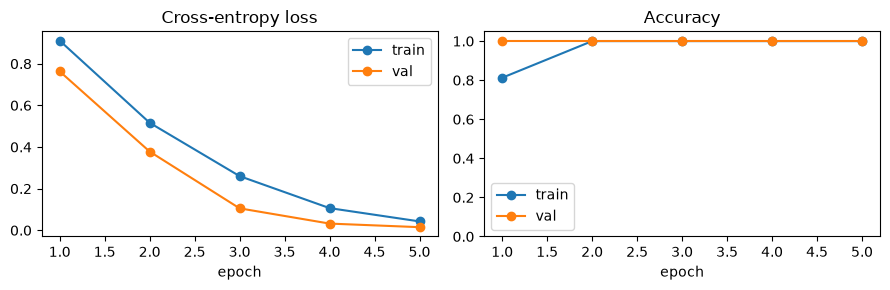

In [30]:
history_df = pd.DataFrame(history)
print(history_df.to_string(index=False))
with TemporaryDirectory() as temp_dir:
    csv_path = Path(temp_dir) / "training_history.csv"
    history_df.to_csv(csv_path, index=False)
    restored_history = pd.read_csv(csv_path)
    assert np.allclose(restored_history["val_loss"], history_df["val_loss"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for split in ("train", "val"):
    axes[0].plot(history_df["epoch"], history_df[f"{split}_loss"], marker="o", label=split)
    axes[1].plot(history_df["epoch"], history_df[f"{split}_accuracy"], marker="o", label=split)
axes[0].set_title("Cross-entropy loss")
axes[1].set_title("Accuracy")
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()


## 13. 保存、加载：权重不是整个 Python 模型

`state_dict()` 是名称到 Tensor 的映射，包含参数和 BatchNorm 等缓冲区，不包含模型类定义。加载时先用一致的结构创建模型，再 `load_state_dict(...)`，最后切换到评估模式。

- `torch.save` 写入文件；`torch.load(..., map_location="cpu", weights_only=True)` 只读取本例所需的权重与安全类型，并将 Tensor 映射到 CPU。
- `weights_only=True` 不是未知文件的安全保证；只加载可信文件。
- 类别映射和预处理与权重同样重要，必须一起保存约定。
- 不用 `strict=False` 隐藏结构/类别数不一致的问题。

如果需要**继续训练**，还要保存优化器状态和训练轮次；若使用学习率调度器、混合精度等，还应保存它们的状态。精确复现中断时的随机序列需要额外保存 RNG 等状态。


In [31]:
# 与 ColorDataset 的 0/1/2 语义一致，而不是按字符串排序重新猜测。
class_names = ["red", "green", "blue"]
model.eval()
probe_images, _ = next(iter(val_loader))
with torch.inference_mode():
    before_save = model(probe_images.to(device)).cpu()

with TemporaryDirectory() as temp_dir:
    checkpoint_path = Path(temp_dir) / "classifier.pth"
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "num_classes": 3,
        "input_size": [24, 24],
        "mean": [0.5, 0.5, 0.5],
        "std": [0.5, 0.5, 0.5],
    }
    torch.save(checkpoint, checkpoint_path)
    loaded = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    inference_model = TinyCNN(num_classes=loaded["num_classes"])
    inference_model.load_state_dict(loaded["model_state_dict"])
    inference_model = inference_model.to(device).eval()
    loaded_class_names = loaded["class_names"]
    with torch.inference_mode():
        after_load = inference_model(probe_images.to(device)).cpu()
    assert torch.allclose(before_save, after_load, atol=1e-6, rtol=1e-5)
    print("save/load preserved logits:", True)

# 独立示例：继续训练时，模型和优化器必须来自同一个训练时刻。
# 上面恢复的是最佳模型，不应与最后一轮优化器状态拼成恢复点。
resume_model = TinyCNN().to(device)
resume_optimizer = torch.optim.Adam(resume_model.parameters(), lr=0.01)
_ = run_epoch(resume_model, train_loader, criterion, device, resume_optimizer)
with TemporaryDirectory() as temp_dir:
    resume_path = Path(temp_dir) / "resume.pth"
    torch.save({"epoch": 1, "model": resume_model.state_dict(),
                "optimizer": resume_optimizer.state_dict()}, resume_path)
    resume = torch.load(resume_path, map_location=device, weights_only=True)
    resume_model.load_state_dict(resume["model"])
    resume_optimizer.load_state_dict(resume["optimizer"])
    print("next epoch:", resume["epoch"] + 1)


save/load preserved logits: True
next epoch: 2


## 14. 单张图片预测：补 batch 维，再把索引翻译成类别

单张 `[C,H,W]` 图像要先 `unsqueeze(0)` 变成 `[1,C,H,W]`。预测必须使用与训练/验证约定一致的通道顺序、尺寸和标准化，且关闭随机增强。

`softmax(dim=1)` 得到各类概率，`max(dim=1)` 同时取最大概率和索引。最大概率不是“模型一定正确”的保证，尤其不能据此判断分布之外的图片。


In [32]:
inference_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.CenterCrop(tuple(loaded["input_size"])),
    transforms.ToTensor(),
    transforms.Normalize(loaded["mean"], loaded["std"]),
])
# 实际读取一张临时图片，演示文件路径 -> PIL -> Tensor -> 模型。
with TemporaryDirectory() as temp_dir:
    image_path = Path(temp_dir) / "green.png"
    Image.new("RGB", (32, 30), color=(20, 230, 20)).save(image_path)
    with Image.open(image_path) as image:
        input_tensor = inference_transform(image.convert("RGB")).unsqueeze(0).to(device)
    inference_model.eval()
    with torch.inference_mode():
        logits = inference_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predicted_index = probabilities.max(dim=1)
    predicted_name = loaded_class_names[predicted_index.item()]
    print("input:", input_tensor.shape)
    print("probabilities:", probabilities.cpu().numpy())
    print("prediction:", predicted_name, f"({confidence.item():.1%})")
    assert predicted_name == "green"


input: torch.Size([1, 3, 24, 24])
probabilities: [[0.23628502 0.5516475  0.21206744]]
prediction: green (55.2%)


## 15. 拓展：常见模型 API：创建结构、替换分类头、冻结参数

`torchvision.models` 提供常见结构。`weights=None` 只创建随机初始化的模型，不下载权重。若显式使用某个权重枚举的 `DEFAULT`，首次使用可能下载，且应使用该权重对象的 `transforms()` 预处理；不要混用旧的 `pretrained=True` 写法与新接口。

下面用较小的 ResNet-18 演示：`.fc.in_features` 查询原分类头的输入宽度，替换 `.fc` 改变类别数。冻结参数使用 `requires_grad_(False)`；这不等于 `eval()`，也不会自动停止 BatchNorm 的运行统计更新。若希望冻结部分保持评估行为，需要在调用整个模型的 `train()` 后，对该部分再设 `eval()`。


In [33]:
backbone = models.resnet18(weights=None)
for parameter in backbone.parameters():
    parameter.requires_grad_(False)
backbone.fc = nn.Linear(backbone.fc.in_features, 3)  # 新层默认仍需梯度
head_optimizer = torch.optim.SGD(
    [p for p in backbone.parameters() if p.requires_grad], lr=0.01
)
print("trainable names:", [name for name, p in backbone.named_parameters() if p.requires_grad])
backbone.eval()
with torch.inference_mode():
    output = backbone(torch.randn(1, 3, 64, 64))
print("torchvision model logits:", output.shape)
assert output.shape == (1, 3)
del backbone, head_optimizer  # 后面不再使用这个独立演示模型


trainable names: ['fc.weight', 'fc.bias']
torchvision model logits: torch.Size([1, 3])


## 16. 高频错误定位表

| 现象 | 先检查什么 |
|---|---|
| `expected ... channels` | 输入是否 NCHW、RGB/灰度是否和 `in_channels` 一致 |
| `mat1 and mat2 shapes cannot be multiplied` | flatten 后宽度是否等于 Linear 的 `in_features`；逐层打印 shape |
| `Sizes of tensors must match` | cat 之外的轴是否相同；分支 padding/stride 是否一致 |
| 残差相加失败 | shortcut 是否同步改变通道数和空间尺寸 |
| `Expected all tensors to be on the same device` | 模型、输入、标签是否都在同一 device |
| 类别标签类型/范围错误 | 是否为 long、shape `[N]`、范围 `[0,K-1]` |
| `does not require grad` | 是否在训练路径里用了 detach、item 或 no_grad |
| 显存/内存持续增加 | 是否把仍连接计算图的 loss/output 存进长期列表；日志存 item 值 |
| 训练不动 | 是否执行 backward 和 step，是否错误关闭梯度，学习率是否合理 |
| 验证结果波动或单张预测不稳 | 是否 eval、是否仍在随机增强、预处理和类别映射是否一致 |
| 加载出现 missing/unexpected keys | 模型结构/层名/类别数是否与保存时一致，不要直接忽略 |

**排错顺序**：先拿一个 batch，打印输入/标签的 shape、dtype、device，再逐段运行 forward；最后检查 loss 和一次参数更新。不要从头猜整个网络。


## 17. 自测：不看上文，能回答才算掌握

1. `[8,3,32,32]` 经过 `Conv2d(3,16,3,padding=1)`、`MaxPool2d(2)`，flatten 后的 shape 是什么？
2. `[8,10]` logits 对应的整数标签应是什么 shape 和 dtype？为什么不能先 Softmax 再传给 CrossEntropyLoss？
3. `eval()` 与 `no_grad()` 分别改变什么？为什么验证通常两者都要用？
4. `torch.cat([a,b],dim=1)` 与 `a+b` 对形状的要求和结果有何不同？
5. 保存“最佳权重”时，为什么不能只写 `best_state = model.state_dict()` 然后继续训练？
6. 如何将一张 PIL 图片变成模型输入，并把输出索引变成正确的类别名称？
7. 若两个 batch 分别有 16、7 个样本，它们的平均 loss 应如何合并？

<details>
<summary>答案与核对点</summary>

1. 卷积后 `[8,16,32,32]`，池化后 `[8,16,16,16]`，flatten 后 `[8,4096]`。
2. `[8]`、`torch.long`；CrossEntropyLoss 内部已做 log-softmax，先 Softmax 会改变本应输入的分数。
3. eval 切换 BatchNorm/Dropout 等层行为；no_grad 关闭计算图记录。一个不能代替另一个。
4. cat 在通道轴累加长度，其他轴要相同；残差相加要求对应位置可对齐，本教程要求完全同形状，不增加通道。
5. state_dict 的值仍引用模型 Tensor，需要 deepcopy、clone 或立即保存文件才能冻结那个时刻的状态。
6. RGB、固定预处理、CHW、补 batch 轴、移到设备、eval 与推理上下文，再按训练时保存的映射查名称。
7. `(loss1*16 + loss2*7)/23`，不是 `(loss1+loss2)/2`。

</details>

**建议动手**：把分类数改为 4 时，追踪数据标签、主/辅助分类头、损失输入和类别映射需要同步修改的位置；把 ResidualBlock 的 stride 改为 2，手算两条支路的 shape 后再运行。

## 18. 官方文档索引

查 API 时优先核对自己安装的版本，尤其是 torchvision 的权重与预处理接口。

- [Tensor 与 torch API](https://docs.pytorch.org/docs/stable/torch.html)
- [自动微分](https://docs.pytorch.org/docs/stable/autograd.html)
- [nn 网络层与损失](https://docs.pytorch.org/docs/stable/nn.html)
- [优化器](https://docs.pytorch.org/docs/stable/optim.html)
- [Dataset 与 DataLoader](https://docs.pytorch.org/docs/stable/data.html)
- [torchvision transforms](https://docs.pytorch.org/vision/stable/transforms.html)
- [ImageFolder](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html)
- [torchvision 模型与权重](https://docs.pytorch.org/vision/stable/models.html)
- [保存与加载](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)
